# Eigenvalues & PCA
*Math foundations, part of my [Data Science Roadmap](../../README.md)*

**Goal:** Build PCA by hand on the Iris dataset: covariance matrix → eigen-decomposition → projection to 2D.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris  # Real data!

In [2]:
# Step 2.1: Load Iris dataset (your 1st ML data!)
iris=load_iris()
X=iris.data # 150 flowers × 4 features (sepal/petal)
print("Iris shape:", X.shape)
print("Features:", iris.feature_names) 

Iris shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [3]:
# Step 2.2: Covariance matrix (data "stretch map")
X_centered = X-X.mean(axis=0)
cov_matrix=np.cov(X_centered,rowvar=False)
print("\nCovariance:\n", cov_matrix.round(2))


Covariance:
 [[ 0.69 -0.04  1.27  0.52]
 [-0.04  0.19 -0.33 -0.12]
 [ 1.27 -0.33  3.12  1.3 ]
 [ 0.52 -0.12  1.3   0.58]]


In [4]:
# Step 2.3: EIGEN MAGIC! (numpy.linalg.eig)
eigenvalues,eigenvectors=np.linalg.eig(cov_matrix)
print("\nEigenvalues:", eigenvalues.round(3))  # Variance along each direction
print("Eigenvectors (directions):\n", eigenvectors.round(3))


Eigenvalues: [4.228+0.j 0.243+0.j 0.078+0.j 0.024+0.j]
Eigenvectors (directions):
 [[ 0.361+0.j -0.657+0.j -0.582+0.j  0.315+0.j]
 [-0.085+0.j -0.73 +0.j  0.598+0.j -0.32 +0.j]
 [ 0.857+0.j  0.173+0.j  0.076+0.j -0.48 +0.j]
 [ 0.358+0.j  0.075+0.j  0.546+0.j  0.754+0.j]]


In [5]:
# Sort by eigenvalue (biggest variance first)
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
print("\nSorted Eigenvalues:", eigenvalues.round(3))
print("Top Eigenvector (PC1):\n", eigenvectors[:, 0].round(3))


Sorted Eigenvalues: [4.228+0.j 0.243+0.j 0.078+0.j 0.024+0.j]
Top Eigenvector (PC1):
 [ 0.361+0.j -0.085+0.j  0.857+0.j  0.358+0.j]


In [6]:
# Step 2.4: PCA Project Data to 2D!
X_pca = X_centered @ eigenvectors[:, :2]  # Top 2 directions

/usr/local/lib/python3.13/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/site-packages/matplotlib/collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


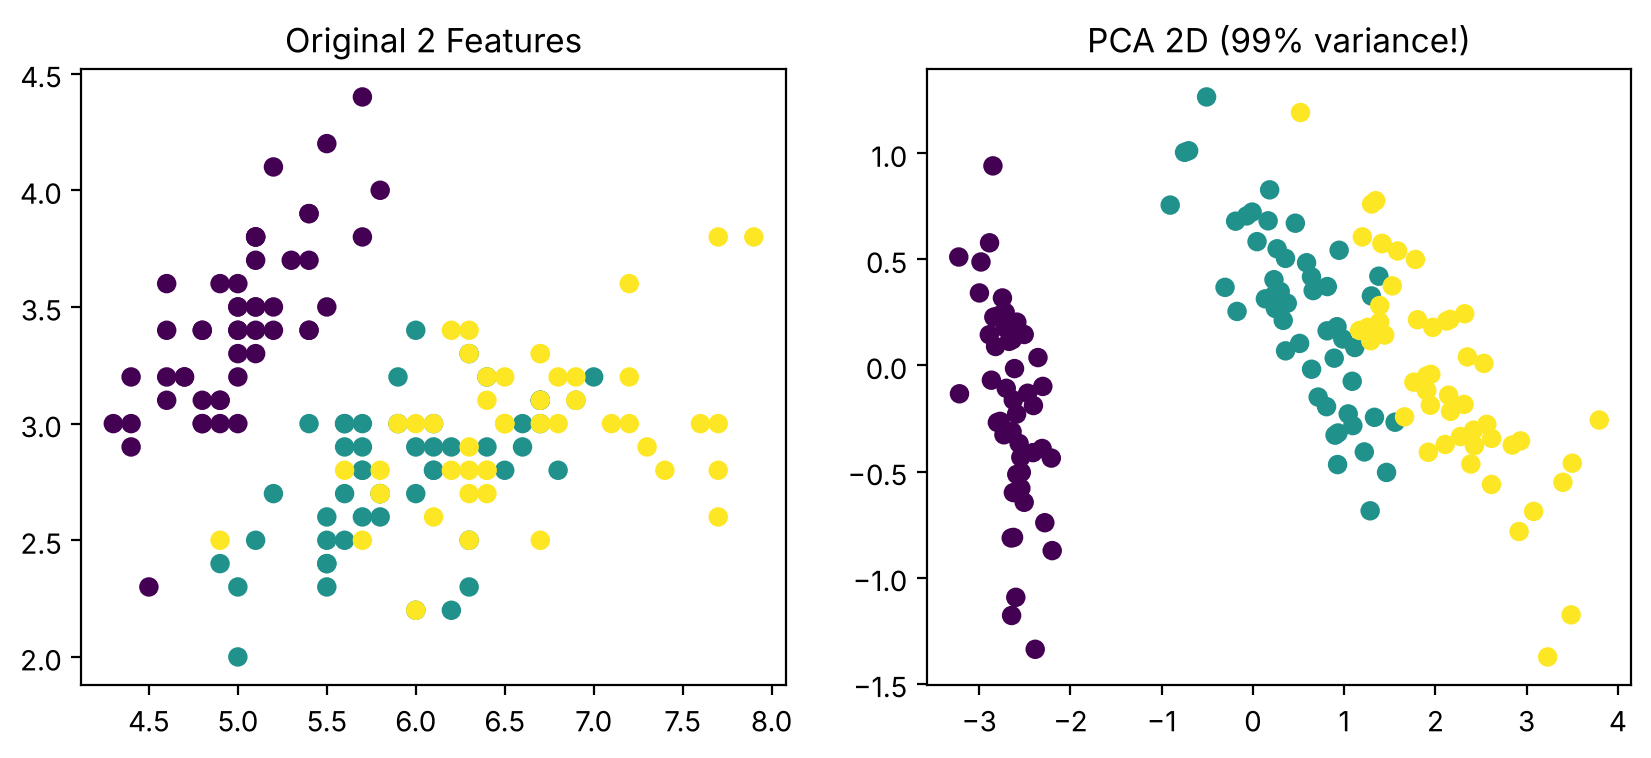

Variance explained by top 2: 97.8+0.0j%


In [7]:
# Visualize
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.scatter(X[:,0], X[:,1], c=iris.target); plt.title('Original 2 Features')
plt.subplot(1,2,2); plt.scatter(X_pca[:,0], X_pca[:,1], c=iris.target); plt.title('PCA 2D (99% variance!)')
plt.show()
print(f"Variance explained by top 2: {eigenvalues[:2].sum() / eigenvalues.sum() * 100:.1f}%")

## Key takeaways
- The **covariance matrix** shows how features vary together
- **Eigenvectors** are the main directions of variance; **eigenvalues** measure how much variance each one carries
- Projecting onto the top 2 eigenvectors keeps most of the information in 2 dimensions